# Análisis de sentimiento de reseñas | WeLoveReviews

Este notebook explora 500 reseñas y compara sus puntuaciones con el modelo `distilbert-base-uncased-finetuned-sst-2-english`. Las estrellas se agrupan como 1–2 negativa, 3 neutral y 4–5 positiva. El modelo SST-2 solo devuelve negativa o positiva: por eso se reportan métricas de tres clases (neutral será un fallo del modelo) y métricas binarias que excluyen reseñas de 3 estrellas.

La comparación con estrellas es una referencia débil, no una etiqueta humana verificada: una puntuación no siempre refleja el tono del texto.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

candidate_roots = [Path.cwd(), Path.cwd().parent, Path.cwd() / "machine-learning-python-GustavoMesa-template"]
PROJECT_ROOT = next((path for path in candidate_roots if (path / "data/raw/reviews.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró data/raw/reviews.csv desde el directorio actual.")

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from app import load_reviews

reviews = load_reviews(PROJECT_ROOT / "data/raw/reviews.csv")
print(f"Filas: {len(reviews):,} | Columnas: {len(reviews.columns)}")
print("Valores ausentes por columna:")
display(reviews.isna().sum().rename("valores ausentes").to_frame())
print(f"Filas duplicadas exactas: {reviews.duplicated().sum()}")
print(f"Textos únicos: {reviews['review_text'].nunique()} de {len(reviews)}")

reviews["word_count"] = reviews["review_text"].str.split().str.len()
rating_counts = reviews["rating"].value_counts().sort_index().reindex(range(1, 6), fill_value=0)
length_summary = reviews["word_count"].describe().round(1)
print("Distribución de puntuaciones:")
display(rating_counts.rename("reseñas").to_frame())
print("Longitud de texto en palabras:")
display(length_summary.to_frame())
print("Ejemplos de reseñas:")
display(reviews[["rating", "review_text"]].head(5))

Filas: 500 | Columnas: 3
Valores ausentes por columna:


,valores ausentes
review_id,0
rating,0
review_text,0


Filas duplicadas exactas: 0
Textos únicos: 493 de 500
Distribución de puntuaciones:


,reseñas
rating,
1,12
2,18
3,38
4,72
5,360


Longitud de texto en palabras:


,word_count
count,500.0
mean,29.1
std,4.8
min,14.0
25%,26.0
50%,29.0
75%,32.0
max,42.0


Ejemplos de reseñas:


,rating,review_text
0,5,Visited Harbor House Café last weekend. Great ...
1,5,Tried Harbor House Café after seeing it recomm...
2,5,Tried Harbor House Café after seeing it recomm...
3,5,Visited Harbor House Café last weekend. The st...
4,5,Grabbed a quick coffee at Harbor House Café th...


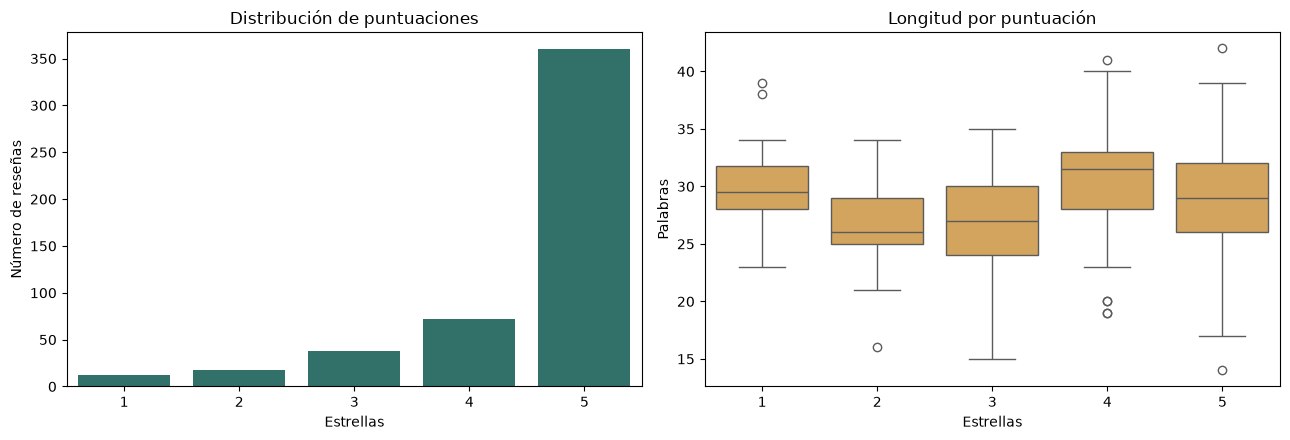

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=rating_counts.index.astype(str), y=rating_counts.values, color="#287a72", ax=axes[0])
axes[0].set(title="Distribución de puntuaciones", xlabel="Estrellas", ylabel="Número de reseñas")
sns.boxplot(data=reviews, x="rating", y="word_count", color="#e5a84b", ax=axes[1])
axes[1].set(title="Longitud por puntuación", xlabel="Estrellas", ylabel="Palabras")
plt.tight_layout()
plt.show()

## Hallazgos del EDA

- La distribución está muy desequilibrada: 360 de 500 reseñas (72 %) tienen 5 estrellas, frente a 30 (6 %) con 1 o 2 estrellas. La exactitud por sí sola puede ocultar un bajo rendimiento en la clase negativa.
- Hay 38 reseñas de 3 estrellas (7,6 %), que se conservarán como neutrales para la matriz de tres clases.
- No hay valores ausentes ni filas duplicadas exactas. Hay 493 textos distintos de 500; por eso algunos textos se repiten aunque las filas completas no sean duplicadas.
- Las reseñas tienen una media de 29,1 palabras (mediana 29; rango 14–42). La longitud sirve para describir los textos, pero no demuestra por sí sola que la puntuación sea correcta.
- La etiqueta derivada de estrellas será una aproximación para comparar con el modelo, no una anotación manual de sentimiento.

## Inferencia con Hugging Face

Esta celda descarga el modelo la primera vez que se ejecuta y clasifica las reseñas en lotes. Se ejecuta en CPU para mantener compatibilidad; las probabilidades del modelo no equivalen a una probabilidad calibrada de que la reseña sea correcta.

In [3]:
from app import add_sentiment_predictions, evaluate_predictions

inference_input = reviews.drop(columns=["word_count"], errors="ignore")
results = add_sentiment_predictions(inference_input)
output_path = PROJECT_ROOT / "data" / "processed" / "reviews_with_sentiment.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(output_path, index=False)

print(f"Reseñas clasificadas: {len(results)}")
print(f"Archivo guardado: {output_path}")
print("Sentimiento asignado desde las estrellas:")
display(results["sentiment_from_rating"].value_counts().reindex(["Negativa", "Neutral", "Positiva"]).rename("reseñas").to_frame())
print("Sentimiento predicho por el modelo:")
display(results["sentiment_model"].value_counts().reindex(["Negativa", "Positiva"]).rename("reseñas").to_frame())
display(results[["review_id", "rating", "sentiment_from_rating", "sentiment_model", "sentiment_score"]].head())

C:\Users\gusta\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device set to use cpu


Reseñas clasificadas: 500
Archivo guardado: C:\Desarrollo\Proyectos\aprendizaje\4geeks\IA\machine-learning-python-GustavoMesa-template\data\processed\reviews_with_sentiment.csv
Sentimiento asignado desde las estrellas:


,reseñas
sentiment_from_rating,
Negativa,30
Neutral,38
Positiva,432


Sentimiento predicho por el modelo:


,reseñas
sentiment_model,
Negativa,55
Positiva,445


,review_id,rating,sentiment_from_rating,sentiment_model,sentiment_score
0,1,5,Positiva,Positiva,0.999504
1,2,5,Positiva,Positiva,0.999858
2,3,5,Positiva,Positiva,0.999673
3,4,5,Positiva,Positiva,0.999848
4,5,5,Positiva,Positiva,0.999857


## Métricas y errores

La matriz de tres clases conserva todas las reseñas; como el modelo no tiene una salida neutral, ninguna reseña de 3 estrellas puede ser clasificada correctamente en esa clase. Para evaluar discriminación polar, la métrica binaria excluye las reseñas neutrales y usa únicamente 1–2 frente a 4–5 estrellas. Un falso positivo es una reseña negativa según estrellas que el modelo llama positiva; un falso negativo es una positiva según estrellas que el modelo llama negativa.

Reporte de tres clases:


,precision,recall,f1-score,support
Negativa,0.545,1.000,0.706,30.000
Neutral,0.000,0.000,0.000,38.000
Positiva,0.971,1.000,0.985,432.000
accuracy,0.924,0.924,0.924,0.924
macro avg,0.505,0.667,0.564,500.000
weighted avg,0.871,0.924,0.894,500.000


Reporte binario (sin reseñas de 3 estrellas):


,precision,recall,f1-score,support
Negativa,1.0,1.0,1.0,30.0
Positiva,1.0,1.0,1.0,432.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,462.0
weighted avg,1.0,1.0,1.0,462.0


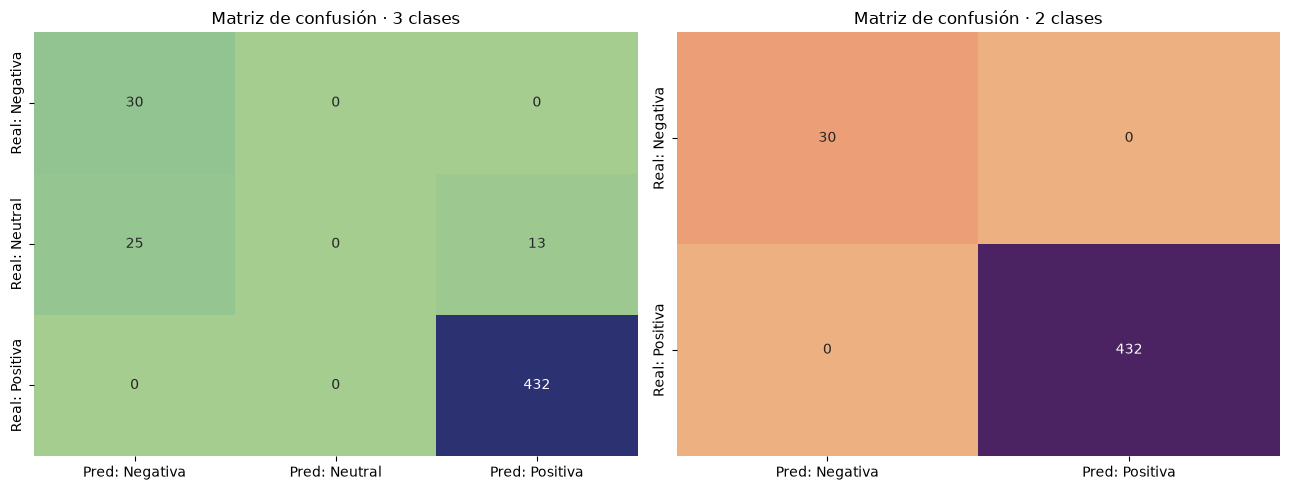

Falsos positivos: 0


,review_id,rating,sentiment_from_rating,sentiment_model,sentiment_score,review_text


Falsos negativos: 0


,review_id,rating,sentiment_from_rating,sentiment_model,sentiment_score,review_text


In [4]:
evaluation = evaluate_predictions(results)
three_class_report = pd.DataFrame(evaluation["three_class_report"]).transpose().round(3)
binary_report = pd.DataFrame(evaluation["binary_report"]).transpose().round(3)
three_class_matrix = pd.DataFrame(
    evaluation["three_class_confusion"],
    index=["Real: " + label for label in ["Negativa", "Neutral", "Positiva"]],
    columns=["Pred: " + label for label in ["Negativa", "Neutral", "Positiva"]],
)
binary_matrix = pd.DataFrame(
    evaluation["binary_confusion"],
    index=["Real: Negativa", "Real: Positiva"],
    columns=["Pred: Negativa", "Pred: Positiva"],
)

print("Reporte de tres clases:")
display(three_class_report)
print("Reporte binario (sin reseñas de 3 estrellas):")
display(binary_report)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(three_class_matrix, annot=True, fmt="d", cmap="crest", cbar=False, ax=axes[0])
axes[0].set_title("Matriz de confusión · 3 clases")
sns.heatmap(binary_matrix, annot=True, fmt="d", cmap="flare", cbar=False, ax=axes[1])
axes[1].set_title("Matriz de confusión · 2 clases")
plt.tight_layout()
plt.show()

error_columns = ["review_id", "rating", "sentiment_from_rating", "sentiment_model", "sentiment_score", "review_text"]
print(f"Falsos positivos: {len(evaluation['false_positives'])}")
display(evaluation["false_positives"][error_columns].head(3))
print(f"Falsos negativos: {len(evaluation['false_negatives'])}")
display(evaluation["false_negatives"][error_columns].head(3))

In [5]:
from IPython.display import Markdown

neutral_recall = evaluation["three_class_report"]["Neutral"]["recall"]
three_class_macro_f1 = evaluation["three_class_report"]["macro avg"]["f1-score"]
binary_macro_f1 = evaluation["binary_report"]["macro avg"]["f1-score"]

conclusion = f"""
### Conclusiones

- El F1 macro de tres clases es **{three_class_macro_f1:.3f}**. El recall neutral es **{neutral_recall:.3f}**, porque el modelo SST-2 no ofrece una etiqueta neutral.
- Al excluir las 3 estrellas, el F1 macro binario es **{binary_macro_f1:.3f}**; se observaron **{len(evaluation['false_positives'])} falsos positivos** y **{len(evaluation['false_negatives'])} falsos negativos** frente a las estrellas agrupadas.
- Interpreta estas métricas teniendo presente el desequilibrio (72 % de reseñas de 5 estrellas) y que las estrellas son una referencia imperfecta de sentimiento. Los casos de error requieren lectura humana antes de sacar conclusiones sobre el servicio.

El archivo procesado contiene las columnas originales, la etiqueta derivada de estrellas, la predicción binaria del modelo y su puntuación de confianza.
"""
display(Markdown(conclusion))


### Conclusiones

- El F1 macro de tres clases es **0.564**. El recall neutral es **0.000**, porque el modelo SST-2 no ofrece una etiqueta neutral.
- Al excluir las 3 estrellas, el F1 macro binario es **1.000**; se observaron **0 falsos positivos** y **0 falsos negativos** frente a las estrellas agrupadas.
- Interpreta estas métricas teniendo presente el desequilibrio (72 % de reseñas de 5 estrellas) y que las estrellas son una referencia imperfecta de sentimiento. Los casos de error requieren lectura humana antes de sacar conclusiones sobre el servicio.

El archivo procesado contiene las columnas originales, la etiqueta derivada de estrellas, la predicción binaria del modelo y su puntuación de confianza.
